# San Luis Valley: find and screen groundwater wells (step 1.6)

Companion to the scene-search notebook. It finds wells in the valley from **USGS** and **Colorado DWR**, counts their water-level observations inside your Sentinel-1 window, sorts them into tiers, and writes two files the other notebook can use.

**Outputs (in `C:/insar`)**
- `wells.csv`: wells with at least a few observations in the window. Columns `name, lon, lat, ...`. Set `WELLS_CSV` in the scene notebook to this path to run the frame-coverage check on real wells.
- `wells_all.csv`: every well found, including those with no data in the window.
- `well_obs.csv`: every observation (source, id, time, depth in ft). Only needed for step 2.4.

**Depth values:** USGS parameter 72019 is depth to water in **feet below land surface**, so a larger number means a deeper water level. DWR units are not verified.

In [1]:
# One-time install, in a terminal inside your conda environment (not in this notebook):
#   python -m pip install requests pandas numpy matplotlib

import os
import re
import json
import time
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

## Settings

The box and window match the scene notebook. The tier cutoffs are my proposals: about monthly or better is needed to see a seasonal cycle, so "frequent" means about monthly (18 or more distinct dates in two years; I first used 24, which is exactly monthly, and that dropped wells that missed a single reading), and "daily" is a continuous sensor.

In [2]:
AOI_BBOX = (-106.7, 37.2, -105.3, 38.4)       # west, south, east, north; same box as the scene notebook
WINDOW = ("2022-01-01", "2023-12-31")         # match your Sentinel-1 window
COUNTIES = ["Alamosa", "Conejos", "Costilla", "Rio Grande", "Saguache"]   # DWR is queried by county
GW_PARAM = "72019"                            # USGS: depth to water, feet below land surface

TIER_DAILY, TIER_FREQUENT, TIER_SPARSE = 300, 18, 4   # distinct dates in the window
DWR_MAX_WELLS = 300                           # DWR needs one request per well; anonymous limit is 1,000 calls/day
EXTRA_WELLS_CSV = None                        # optional: CSV with columns name, lon, lat (e.g. RGWCD telemetry wells)

DATA_DIR = Path("C:/insar")                   # keep this path short on Windows
OUT_WELLS, OUT_ALL, OUT_OBS = DATA_DIR / "wells.csv", DATA_DIR / "wells_all.csv", DATA_DIR / "well_obs.csv"
CACHE_DIR = DATA_DIR / "cache_wells"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

## Request helpers

Throttled, cached and retried, because the USGS API rate-limits. A free USGS API key raises the limit. Responses are cached for 6 hours, so re-running a cell is cheap.

In [3]:
USGS_BASE = "https://api.waterdata.usgs.gov/ogcapi/v0"
DWR_BASE = "https://dwr.state.co.us/Rest/GET/api/v2/groundwater/waterlevels"


def load_env(names=(".env", "env")):
    """Find the env file in the working dir or any parent, load its KEY=VALUE lines into os.environ."""
    for d in [Path.cwd(), *Path.cwd().parents]:
        for name in names:
            f = d / name
            if f.is_file():
                for line in f.read_text(encoding="utf-8-sig").splitlines():
                    line = line.strip()
                    if not line or line.startswith("#") or "=" not in line:
                        continue
                    k, v = line.split("=", 1)
                    if not os.environ.get(k.strip()):
                        os.environ[k.strip()] = v.strip().strip('"').strip("'")
                return f
    return None


ENV_FILE = load_env()
USGS_KEY = os.environ.get("USGS_API_KEY") or None
DWR_KEY = os.environ.get("CDSS_API_KEY") or None       # optional
print("env file:", ENV_FILE or "NOT FOUND (looked in the notebook folder and its parents)")
MIN_INTERVAL = 0.3 if USGS_KEY else 1.0
_last = [0.0]


def _get_json(url, query=None, headers=None, retries=6, ttl_hours=6):
    key = hashlib.md5(f"{url}|{sorted((query or {}).items())}".encode()).hexdigest()
    cache_file = CACHE_DIR / f"{key}.json"
    if cache_file.exists() and time.time() - cache_file.stat().st_mtime < ttl_hours * 3600:
        return json.loads(cache_file.read_text())
    for attempt in range(retries):
        wait = MIN_INTERVAL - (time.time() - _last[0])
        if wait > 0:
            time.sleep(wait)
        resp = requests.get(url, params=query, headers=headers or {}, timeout=60)
        _last[0] = time.time()
        if resp.status_code in (429, 500, 502, 503, 504):
            delay = float(resp.headers.get("Retry-After", min(2 ** attempt * 2, 120)))
            print(f"  HTTP {resp.status_code}; sleeping {delay:.0f}s (attempt {attempt + 1}/{retries})")
            time.sleep(delay)
            continue
        if resp.status_code >= 400:
            raise requests.HTTPError(f"{resp.status_code} for {resp.url}\n{resp.text[:400]}", response=resp)
        js = resp.json()
        cache_file.write_text(json.dumps(js))
        return js
    raise RuntimeError(f"Gave up after {retries} tries: {url}")


def ogc_get(collection, max_pages=100, **params):
    """USGS OGC API: GET /collections/{collection}/items, follow pagination, return a DataFrame
    (feature properties as columns, point geometry as longitude/latitude)."""
    query = {k: v for k, v in params.items() if v is not None}
    query.setdefault("f", "json")
    query.setdefault("limit", 10000)
    headers = {"X-Api-Key": USGS_KEY} if USGS_KEY else {}
    url, rows, pages = f"{USGS_BASE}/collections/{collection}/items", [], 0
    while url and pages < max_pages:
        js = _get_json(url, query, headers)
        for feat in js.get("features", []):
            row = dict(feat.get("properties") or {})
            row["feature_id"] = feat.get("id")
            geom = feat.get("geometry") or {}
            if geom.get("type") == "Point":
                row["longitude"], row["latitude"] = geom["coordinates"][:2]
            rows.append(row)
        url = next((l["href"] for l in js.get("links", []) if l.get("rel") == "next"), None)
        query = None   # the "next" link already carries the full query string
        pages += 1
    return pd.DataFrame(rows)


def dwr_get(endpoint, max_pages=20, **params):
    """Colorado DWR groundwater water-level endpoints; results arrive in a 'ResultList' wrapper."""
    query = {"format": "json", "dateFormat": "spaceSepToSeconds", "pageSize": 50000, **params}
    if DWR_KEY:
        query["apiKey"] = DWR_KEY
    rows, page = [], 1
    while page <= max_pages:
        js = _get_json(f"{DWR_BASE}/{endpoint}/", {**query, "pageIndex": page})
        res = js.get("ResultList", [])
        rows += res
        if len(res) < query["pageSize"]:
            break
        page += 1
    return pd.DataFrame(rows)


def pick(df, *patterns):
    """First column whose name matches one of the regex patterns (in order of preference)."""
    for p in patterns:
        for c in df.columns:
            if re.search(p, str(c), re.I):
                return c
    return None


bbox = ",".join(map(str, AOI_BBOX))


def in_aoi(lon, lat):
    return (lon >= AOI_BBOX[0]) & (lon <= AOI_BBOX[2]) & (lat >= AOI_BBOX[1]) & (lat <= AOI_BBOX[3])


print("Ready. USGS key set:", bool(USGS_KEY), "| DWR key set:", bool(DWR_KEY))

env file: C:\Users\lilli\work\classes\gpgn438-design-drought-analysis\env
Ready. USGS key set: True | DWR key set: False


## USGS: sites, then observations

Sites come from `monitoring-locations` (type GW, Colorado, inside your box). Observations come from two collections queried by box and time window: `field-measurements` (manual tape-downs) and `daily` (daily values from continuous sensors). If a collection errors, the notebook says so and carries on without it.

In [4]:
try:
    us = ogc_get("monitoring-locations", state_name="Colorado", site_type_code="GW", bbox=bbox)
except requests.HTTPError as e:
    print("bbox query failed; falling back to statewide plus a local filter:", str(e)[:200])
    us = ogc_get("monitoring-locations", state_name="Colorado", site_type_code="GW")
if "monitoring_location_id" not in us.columns:
    us["monitoring_location_id"] = us["feature_id"]
us = us.drop_duplicates("monitoring_location_id")
us = us[in_aoi(us["longitude"], us["latitude"])].reset_index(drop=True)
print(len(us), "USGS groundwater sites in the box")
print("columns returned:", list(us.columns))

1641 USGS groundwater sites in the box
columns returned: ['id', 'agency_code', 'agency_name', 'monitoring_location_number', 'monitoring_location_name', 'district_code', 'country_code', 'country_name', 'state_code', 'state_name', 'county_code', 'county_name', 'minor_civil_division_code', 'site_type_code', 'site_type', 'hydrologic_unit_code', 'basin_code', 'altitude', 'altitude_accuracy', 'altitude_method_code', 'altitude_method_name', 'vertical_datum', 'vertical_datum_name', 'horizontal_positional_accuracy_code', 'horizontal_positional_accuracy', 'horizontal_position_method_code', 'horizontal_position_method_name', 'original_horizontal_datum', 'original_horizontal_datum_name', 'drainage_area', 'contributing_drainage_area', 'time_zone_abbreviation', 'uses_daylight_savings', 'construction_date', 'aquifer_code', 'national_aquifer_code', 'aquifer_type_code', 'well_constructed_depth', 'hole_constructed_depth', 'depth_source_code', 'revision_note', 'revision_created', 'revision_modified', 'fe

In [5]:
TIME = f"{WINDOW[0]}T00:00:00Z/{WINDOW[1]}T23:59:59Z"
OBS_COLS = ["source", "kind", "id", "time", "depth_ft"]


def usgs_obs(collection, kind):
    try:
        df = ogc_get(collection, bbox=bbox, parameter_code=GW_PARAM, time=TIME)
    except requests.HTTPError as e:
        print(f"{collection}: FAILED, continuing without it:\n  {str(e)[:300]}")
        return pd.DataFrame(columns=OBS_COLS)
    if df.empty:
        print(f"{collection}: no rows in the window")
        return pd.DataFrame(columns=OBS_COLS)
    if "statistic_id" in df.columns and (df["statistic_id"] == "00003").any():
        df = df[df["statistic_id"] == "00003"]     # daily mean only, so min/max are not double counted
    df = df[df["monitoring_location_id"].isin(us["monitoring_location_id"])]
    out = pd.DataFrame({
        "source": "USGS", "kind": kind, "id": df["monitoring_location_id"].astype(str),
        "time": pd.to_datetime(df["time"], utc=True, errors="coerce"),
        "depth_ft": pd.to_numeric(df["value"], errors="coerce"),
    }).dropna(subset=["time", "depth_ft"])
    print(f"{collection}: {len(out)} observations at {out['id'].nunique()} sites")
    return out


usgs_daily = usgs_obs("daily", "daily")
usgs_field = usgs_obs("field-measurements", "field")

daily: 730 observations at 1 sites
field-measurements: 266 observations at 110 sites


## Colorado DWR: wells by county, then measurements per well

DWR has no box filter, so wells are fetched by county and clipped to your box. Measurements need one request per well, capped by `DWR_MAX_WELLS`. The anonymous limit is 1,000 calls and 600,000 rows per day. If column names are not recognised, the cell stops and prints the columns it received.

In [6]:
parts = []
for c in COUNTIES:
    try:
        d = dwr_get("wells", county=c.upper())
        print(f"DWR wells, {c}: {len(d)}")
        parts.append(d)
    except requests.HTTPError as e:
        print(f"DWR wells, {c}: FAILED, skipping:\n  {str(e)[:300]}")
dw = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

if dw.empty:
    print("No DWR wells returned; continuing with USGS only.")
    dwr_wells = pd.DataFrame(columns=["source", "id", "name_api", "lon", "lat", "county", "land_surface_alt",
                                      "usgs_site", "por_start", "por_end", "por_count", "well_depth", "aquifer"])
else:
    cols = {"id": pick(dw, r"^well_?id$", r"well_?id", r"^id$"), "lat": pick(dw, r"^lat", r"latitude"),
            "lon": pick(dw, r"^lon", r"longitude"), "name": pick(dw, r"well_?name", r"^name$"),
            "county": pick(dw, r"^county"), "elev": pick(dw, r"^elevation$", r"altitude"),
            "usgs": pick(dw, r"^usgsSiteId$"), "por_start": pick(dw, r"^porStart$"),
            "por_end": pick(dw, r"^porEnd$"), "por_count": pick(dw, r"^porCount$"),
            "depth": pick(dw, r"^wellDepth$"), "aquifer": pick(dw, r"^aquifers?$")}
    print("DWR columns matched:", cols)
    print("All DWR columns:", list(dw.columns))
    if None in (cols["id"], cols["lat"], cols["lon"]):
        raise ValueError("Could not find id/lat/lon columns in the DWR wells table. Send Claude the column list above.")
    dwr_wells = pd.DataFrame({
        "source": "DWR", "id": dw[cols["id"]].astype(str),
        "name_api": dw[cols["name"]] if cols["name"] else "",
        "lon": pd.to_numeric(dw[cols["lon"]], errors="coerce"), "lat": pd.to_numeric(dw[cols["lat"]], errors="coerce"),
        "county": dw[cols["county"]] if cols["county"] else "",
        "land_surface_alt": pd.to_numeric(dw[cols["elev"]], errors="coerce") if cols["elev"] else np.nan,
        "usgs_site": dw[cols["usgs"]].astype(str).str.strip() if cols["usgs"] else "",
        "por_start": pd.to_datetime(dw[cols["por_start"]], errors="coerce") if cols["por_start"] else pd.NaT,
        "por_end": pd.to_datetime(dw[cols["por_end"]], errors="coerce") if cols["por_end"] else pd.NaT,
        "por_count": pd.to_numeric(dw[cols["por_count"]], errors="coerce") if cols["por_count"] else np.nan,
        "well_depth": pd.to_numeric(dw[cols["depth"]], errors="coerce") if cols["depth"] else np.nan,
        "aquifer": dw[cols["aquifer"]].astype(str) if cols["aquifer"] else "",
    }).dropna(subset=["lon", "lat"]).drop_duplicates("id")
    dwr_wells = dwr_wells[in_aoi(dwr_wells["lon"], dwr_wells["lat"])].reset_index(drop=True)
    print(len(dwr_wells), "DWR water-level wells in the box")

    # DWR lists each well's period of record, so skip wells that have no data in the window
    w0, w1 = pd.Timestamp(WINDOW[0]), pd.Timestamp(WINDOW[1])
    overlap = (dwr_wells["por_end"] >= w0) & (dwr_wells["por_start"] <= w1)
    dwr_wells = dwr_wells[overlap | dwr_wells["por_end"].isna()]
    dwr_wells = dwr_wells.sort_values("por_count", ascending=False, na_position="last").reset_index(drop=True)
print(len(dwr_wells), "DWR wells have a period of record overlapping the window (most-measured first)")

DWR wells, Alamosa: 422
DWR wells, Conejos: 106
DWR wells, Costilla: 80
DWR wells, Rio Grande: 137
DWR wells, Saguache: 327
DWR columns matched: {'id': 'wellId', 'lat': 'latitude', 'lon': 'longitude', 'name': 'wellName', 'county': 'county', 'elev': 'elevation', 'usgs': 'usgsSiteId', 'por_start': 'porStart', 'por_end': 'porEnd', 'por_count': 'porCount', 'depth': 'wellDepth', 'aquifer': 'aquifers'}
All DWR columns: ['wellId', 'wellName', 'receipt', 'permit', 'wellDepth', 'measurementDate', 'waterLevelDepth', 'waterLevelElevation', 'measurementBy', 'porStart', 'porEnd', 'porCount', 'publicationName', 'aquifers', 'elevation', 'elevationAccuracy', 'topPerforatedCasing', 'bottomPerforatedCasing', 'baseOfGrout', 'wdid', 'locationNumber', 'usgsSiteId', 'contact', 'division', 'waterDistrict', 'county', 'designatedBasin', 'managementDistrict', 'q10', 'q40', 'q160', 'section', 'township', 'range', 'pm', 'coordinatesEw', 'coordinatesEwDir', 'coordinatesNs', 'coordinatesNsDir', 'utmX', 'utmY', 'lat

In [7]:
def mdy(d):
    return pd.Timestamp(d).strftime("%m-%d-%Y")


dwr_obs = pd.DataFrame(columns=OBS_COLS)
todo = dwr_wells.head(DWR_MAX_WELLS)
if len(dwr_wells) > DWR_MAX_WELLS:
    print(f"WARNING: {len(dwr_wells)} DWR wells in the box; only the first {DWR_MAX_WELLS} are queried. Raise DWR_MAX_WELLS to get the rest.")

frames, n_empty = [], 0
for i, wid in enumerate(todo["id"], 1):
    if i % 50 == 0:
        print(f"  {i}/{len(todo)} wells queried")
    try:
        m = dwr_get("wellmeasurements", wellId=wid,
                    **{"min-measurementDate": mdy(WINDOW[0]), "max-measurementDate": mdy(WINDOW[1])})
    except requests.HTTPError as e:
        if e.response is not None and e.response.status_code == 404:   # DWR returns 404 when a well has no rows in the window
            n_empty += 1
            continue
        print(f"well {wid}: FAILED ({str(e)[:160]}); stopping DWR measurements here")
        break
    if len(m):
        m["_wid"] = wid
        frames.append(m)
print(f"{len(todo)} wells in the query list; {n_empty} returned no rows (HTTP 404)")

if frames:
    m = pd.concat(frames, ignore_index=True)
    c_date = pick(m, r"measurement_?date", r"date")
    c_depth = pick(m, r"^depthWaterBelowLandSurface$", r"^depthToWater$", r"depth", r"water_?level")
    print("DWR measurement columns matched: date =", c_date, "| depth =", c_depth)
    print("All measurement columns:", list(m.columns))
    if c_date is None or c_depth is None:
        raise ValueError("Could not find date/depth columns in DWR measurements. Send Claude the column list above.")
    dwr_obs = pd.DataFrame({
        "source": "DWR", "kind": "dwr", "id": m["_wid"].astype(str),
        "time": pd.to_datetime(m[c_date], utc=True, errors="coerce"),
        "depth_ft": pd.to_numeric(m[c_depth], errors="coerce"),
    }).dropna(subset=["time", "depth_ft"])
    missing = dwr_obs["depth_ft"] < -9000          # DWR writes -999999 where a reading is missing
    print(f"DWR: dropped {int(missing.sum())} missing-value rows (depth below -9000)")
    dwr_obs = dwr_obs[~missing]
    keep = (dwr_obs["time"] >= pd.Timestamp(WINDOW[0], tz="UTC")) & (dwr_obs["time"] <= pd.Timestamp(WINDOW[1], tz="UTC") + pd.Timedelta(days=1))
    dwr_obs = dwr_obs[keep]
    print(f"DWR: {len(dwr_obs)} observations at {dwr_obs['id'].nunique()} wells "
          f"({dwr_obs['time'].min().date()} to {dwr_obs['time'].max().date()}); check these dates match your window")
else:
    print("No DWR measurements in the window.")

  50/188 wells queried
  100/188 wells queried
  150/188 wells queried
188 wells in the query list; 0 returned no rows (HTTP 404)
DWR measurement columns matched: date = measurementDate | depth = depthWaterBelowLandSurface
All measurement columns: ['wellId', 'wellName', 'division', 'waterDistrict', 'county', 'managementDistrict', 'designatedBasin', 'publication', 'measurementDate', 'depthToWater', 'measuringPointAboveLandSurface', 'depthWaterBelowLandSurface', 'elevationOfWater', 'delta', 'dataSource', 'published', 'modified', '_wid']
DWR: dropped 3 missing-value rows (depth below -9000)
DWR: 3085 observations at 186 wells (2022-01-01 to 2023-12-31); check these dates match your window


## Combine, tier and flag duplicates

Tiers use the number of **distinct dates** with an observation in your window. A well in both USGS and DWR can appear twice under different ids, so DWR wells within 150 m of a USGS well get a `dup_of` flag. Both rows are kept, so decide which source to use.

In [8]:
obs = pd.concat([usgs_daily, usgs_field, dwr_obs], ignore_index=True)
obs["date"] = obs["time"].dt.tz_convert("UTC").dt.date

rows = []
for (src, wid), g in obs.groupby(["source", "id"]):
    d = pd.to_datetime(pd.Series(sorted(set(g["date"]))))
    rows.append({
        "source": src, "id": wid, "n_dates": len(d),
        "n_daily": g.loc[g["kind"] == "daily", "date"].nunique(),
        "n_manual": g.loc[g["kind"] != "daily", "date"].nunique(),
        "first": d.min().date(), "last": d.max().date(),
        "max_gap_days": d.diff().dt.days.max() if len(d) > 1 else np.nan,
    })
summ = pd.DataFrame(rows, columns=["source", "id", "n_dates", "n_daily", "n_manual", "first", "last", "max_gap_days"])


def tier(n):
    if pd.isna(n) or n == 0:
        return "none"
    return "daily" if n >= TIER_DAILY else "frequent" if n >= TIER_FREQUENT else "sparse" if n >= TIER_SPARSE else "very sparse"


usgs_w = pd.DataFrame({
    "source": "USGS", "id": us["monitoring_location_id"].astype(str),
    "name_api": us["monitoring_location_name"] if "monitoring_location_name" in us.columns else "",
    "lon": us["longitude"], "lat": us["latitude"],
    "county": us["county_name"] if "county_name" in us.columns else "",
    "land_surface_alt": pd.to_numeric(us["altitude"], errors="coerce") if "altitude" in us.columns else np.nan,
    "well_depth": pd.to_numeric(us["well_constructed_depth"], errors="coerce") if "well_constructed_depth" in us.columns else np.nan,
    "aquifer": (us["aquifer_code"].astype(str) + " / type " + us["aquifer_type_code"].astype(str))
               if {"aquifer_code", "aquifer_type_code"} <= set(us.columns) else "",
})
wells = pd.concat([usgs_w, dwr_wells], ignore_index=True).merge(summ, on=["source", "id"], how="left")
for c in ("n_dates", "n_daily", "n_manual"):
    wells[c] = wells[c].fillna(0).astype(int)
wells["tier"] = wells["n_dates"].map(tier)

# DWR wells within 150 m of a USGS well
wells["dup_of"] = ""
u = wells[wells["source"] == "USGS"]
usgs_ids = set(u["id"])
for idx, r in wells[wells["source"] == "DWR"].iterrows():
    sid = str(r["usgs_site"]).strip() if pd.notna(r["usgs_site"]) else ""
    if sid and f"USGS-{sid}" in usgs_ids:          # DWR lists the matching USGS site number
        wells.at[idx, "dup_of"] = f"USGS-{sid}"
        continue
    dx = (u["lon"] - r["lon"]) * np.cos(np.radians(r["lat"])) * 111.32
    dy = (u["lat"] - r["lat"]) * 110.57
    dist = np.hypot(dx, dy)
    if len(dist) and dist.min() < 0.15:
        wells.at[idx, "dup_of"] = u.loc[dist.idxmin(), "id"]

print((wells["dup_of"] != "").sum(), "DWR wells flagged as duplicates of a USGS well")

if EXTRA_WELLS_CSV:
    ex = pd.read_csv(EXTRA_WELLS_CSV)
    ex = pd.DataFrame({"source": "manual", "id": ex["name"].astype(str), "name_api": ex["name"].astype(str),
                       "lon": ex["lon"], "lat": ex["lat"], "tier": "no data fetched"})
    wells = pd.concat([wells, ex], ignore_index=True)
    print(len(ex), "manual wells added (no observations fetched for these)")

wells["name"] = wells["source"] + ":" + wells["id"]
print("Wells by tier (distinct dates in the window):")
print(wells.groupby(["source", "tier"]).size().unstack(fill_value=0))

186 DWR wells flagged as duplicates of a USGS well
Wells by tier (distinct dates in the window):
tier    daily  frequent  none  sparse  very sparse
source                                            
DWR         1        90     2      17           78
USGS        1         0  1531      11           98


In [9]:
show = wells[wells["tier"].isin(["daily", "frequent"])].sort_values("n_dates", ascending=False)
print(len(show), "wells with daily or frequent records. Best candidates:")
show[["name", "county", "n_dates", "n_daily", "n_manual", "first", "last", "max_gap_days", "lon", "lat", "dup_of"]].head(25)

92 wells with daily or frequent records. Best candidates:


,name,county,n_dates,n_daily,n_manual,first,last,max_gap_days,lon,lat,dup_of
686,USGS:USGS-374012105410401,Alamosa County,730,730,33,2022-01-01,2023-12-31,1.0,-105.684889,37.671139,
1641,DWR:31814,ALAMOSA,730,0,730,2022-01-01,2023-12-31,1.0,-105.685032,37.670010,USGS-374012105410401
1643,DWR:6426,ALAMOSA,24,0,24,2022-01-11,2023-12-01,41.0,-106.039758,37.577231,USGS-373438106022101
1644,DWR:5773,ALAMOSA,24,0,24,2022-01-12,2023-12-01,40.0,-105.859475,37.575842,USGS-373433105513201
1648,DWR:6694,SAGUACHE,24,0,24,2022-01-10,2023-12-11,42.0,-106.033644,37.993895,USGS-375938106015901
1645,DWR:5837,SAGUACHE,24,0,24,2022-01-10,2023-12-11,42.0,-105.812804,38.024452,USGS-380128105484401
1646,DWR:6602,ALAMOSA,24,0,24,2022-01-11,2023-12-04,40.0,-105.927527,37.660844,USGS-373941105553802
1647,DWR:6824,SAGUACHE,24,0,24,2022-01-12,2023-12-01,40.0,-106.035306,37.923339,USGS-375524106020501
1650,DWR:6802,SAGUACHE,24,0,24,2022-01-12,2023-12-01,40.0,-105.926414,37.890007,USGS-375324105553301
1649,DWR:6414,CONEJOS,24,0,24,2022-01-13,2023-12-07,39.0,-106.040589,37.400563,USGS-372403106022401


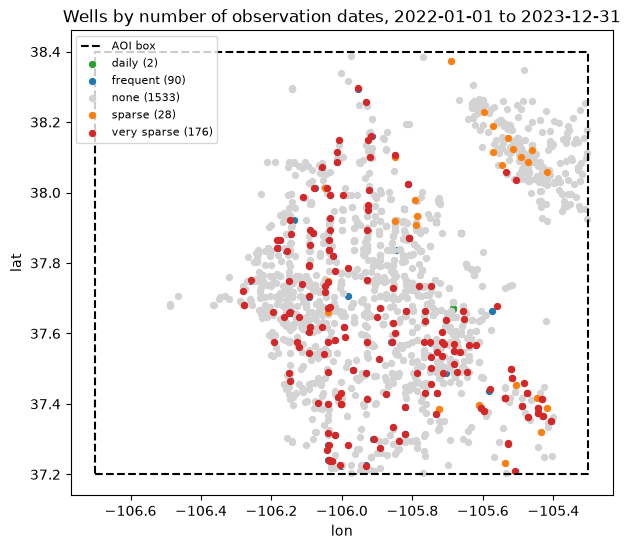

In [10]:
colors = {"daily": "tab:green", "frequent": "tab:blue", "sparse": "tab:orange", "very sparse": "tab:red",
          "none": "lightgrey", "no data fetched": "black"}
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([AOI_BBOX[0], AOI_BBOX[2], AOI_BBOX[2], AOI_BBOX[0], AOI_BBOX[0]],
        [AOI_BBOX[1], AOI_BBOX[1], AOI_BBOX[3], AOI_BBOX[3], AOI_BBOX[1]], "k--", label="AOI box")
for t, g in wells.groupby("tier"):
    ax.scatter(g["lon"], g["lat"], s=18, color=colors.get(t, "grey"), label=f"{t} ({len(g)})")
ax.set_xlabel("lon"); ax.set_ylabel("lat"); ax.set_aspect("equal")
ax.set_title(f"Wells by number of observation dates, {WINDOW[0]} to {WINDOW[1]}")
ax.legend(fontsize=8)
plt.show()

## Save

`wells.csv` keeps wells with at least `TIER_SPARSE` dates (plus any manual wells), because a well with one or two readings cannot show a seasonal cycle. `wells_all.csv` keeps everything.

In [11]:
keep = wells[(wells["n_dates"] >= TIER_SPARSE) | (wells["source"] == "manual")]
keep[["name", "lon", "lat", "source", "id", "county", "tier", "n_dates", "n_daily", "n_manual",
      "first", "last", "max_gap_days", "land_surface_alt", "well_depth", "aquifer", "dup_of"]].to_csv(OUT_WELLS, index=False)
wells.drop(columns=["name_api"]).to_csv(OUT_ALL, index=False)
obs[OBS_COLS].to_csv(OUT_OBS, index=False)
print(f"Saved {len(keep)} wells to {OUT_WELLS}")
print(f"Saved all {len(wells)} wells to {OUT_ALL}")
print(f"Saved {len(obs)} observations to {OUT_OBS}")
print()
print("Next: in the scene notebook set WELLS_CSV =", repr(str(OUT_WELLS).replace(chr(92), '/')), "and re-run the frame-coverage cell.")

Saved 120 wells to C:\insar\wells.csv
Saved all 1829 wells to C:\insar\wells_all.csv
Saved 4081 observations to C:\insar\well_obs.csv

Next: in the scene notebook set WELLS_CSV = 'C:/insar/wells.csv' and re-run the frame-coverage cell.
